# Radiación electromagnética

La energía se transfiere de tres formas: por conducción, cuando las moléculas más energéticas ceden energía a las vecinas por choque; por convección, cuando la energía viaja con el movimiento de un fluido; y por radiación, cuando la materia emite energía en forma de ondas electromagnéticas que se propagan incluso en el vacío a la velocidad de la luz. La teledetección se basa en esta última forma: todo lo que mide un sensor es radiación electromagnética {cite}`chuvieco2008`.

## Onda y partícula

La radiación electromagnética tiene una doble naturaleza. Como onda, está formada por un campo eléctrico y uno magnético que oscilan perpendiculares entre sí y a la dirección de propagación, y se describe por su longitud de onda $\lambda$ y su frecuencia $\nu$, relacionadas por la velocidad de la luz:

$$c = \lambda \, \nu, \qquad c \approx 3 \times 10^8 \ \mathrm{m\,s^{-1}}.$$

El experimento de la doble rendija de Young mostró su carácter ondulatorio a través de la interferencia. Como partícula, la radiación viaja en paquetes discretos de energía, los fotones, cuya energía es proporcional a la frecuencia según la relación de Planck:

$$E = h\,\nu = \frac{h\,c}{\lambda}, \qquad h = 6.626 \times 10^{-34}\ \mathrm{J\,s}.$$

De aquí sale una consecuencia práctica: los fotones de longitudes de onda largas, como las microondas, tienen poca energía, y por eso un sensor pasivo de microondas necesita "mirar" un área grande o integrar mucho tiempo para reunir una señal medible. Es una de las razones por las que la resolución espacial de los sensores térmicos y de microondas pasivos es menor que la de los ópticos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

h, c, k = 6.626e-34, 2.998e8, 1.381e-23
for nombre, lam in [('azul', 0.45e-6), ('infrarrojo cercano', 0.85e-6),
                    ('infrarrojo térmico', 11e-6), ('microondas (banda C)', 5.6e-2)]:
    E = h * c / lam
    print(f'{nombre:22s} lambda = {lam:9.2e} m   E = {E:9.2e} J   ({E/1.602e-19:8.2e} eV)')

azul                   lambda =  4.50e-07 m   E =  4.41e-19 J   (2.76e+00 eV)
infrarrojo cercano     lambda =  8.50e-07 m   E =  2.34e-19 J   (1.46e+00 eV)
infrarrojo térmico     lambda =  1.10e-05 m   E =  1.81e-20 J   (1.13e-01 eV)
microondas (banda C)   lambda =  5.60e-02 m   E =  3.55e-24 J   (2.21e-05 eV)


## El espectro electromagnético

El espectro electromagnético ordena la radiación por longitud de onda, desde los rayos gamma, de picómetros, hasta las ondas de radio, de metros o kilómetros. Para la teledetección interesan unas pocas regiones: el visible (0.4 a 0.7 µm), que el ojo percibe como azul, verde y rojo; el infrarrojo cercano (0.7 a 1.3 µm) y el infrarrojo de onda corta (1.3 a 3 µm), dominados por la radiación solar reflejada; el infrarrojo térmico (3 a 15 µm), dominado por la radiación emitida por la propia superficie; y las microondas (1 mm a 1 m), que usan los radares {cite}`lillesand2015,tempfli2009`.

Las magnitudes radiométricas que se usan con más frecuencia son la energía radiante (J), el flujo radiante o potencia (W), la irradiancia, que es el flujo que incide sobre una unidad de área (W m⁻²), y la radiancia, que es el flujo que sale de una unidad de área en una dirección por unidad de ángulo sólido (W m⁻² sr⁻¹). Los sensores miden radiancia. La reflectividad, la absortividad y la transmisividad son cocientes adimensionales entre el flujo reflejado, absorbido o transmitido y el flujo incidente, y por conservación de la energía suman uno.

## Radiación de un cuerpo negro

Todo cuerpo con temperatura mayor que el cero absoluto emite radiación. Un cuerpo negro es un emisor ideal que absorbe toda la radiación que recibe y emite el máximo posible a cada temperatura. La ley de Planck da su radiancia espectral:

$$B_\lambda(T) = \frac{2 h c^2}{\lambda^5} \, \frac{1}{e^{hc/(\lambda k T)} - 1},$$

donde $k = 1.381 \times 10^{-23}$ J K⁻¹ es la constante de Boltzmann. Dos leyes se derivan de ella. La ley de Stefan-Boltzmann dice que la emitancia total crece con la cuarta potencia de la temperatura, $M = \sigma T^4$ con $\sigma = 5.67 \times 10^{-8}$ W m⁻² K⁻⁴. La ley de desplazamiento de Wien dice que la longitud de onda del máximo de emisión es inversamente proporcional a la temperatura, $\lambda_{max} = 2898 / T$ (en µm, con $T$ en kelvin).

El Sol, con unos 5800 K, tiene su máximo cerca de 0.5 µm, en el verde, y por eso nuestros ojos evolucionaron para ver en esa región. La Tierra, con unos 300 K, emite con un máximo cerca de 10 µm, en el infrarrojo térmico. Las dos curvas casi no se traslapan, y eso define dos dominios de la teledetección pasiva: el de la energía solar reflejada, por debajo de unos 3 µm, y el de la energía emitida por la superficie, por encima de unos 5 µm.

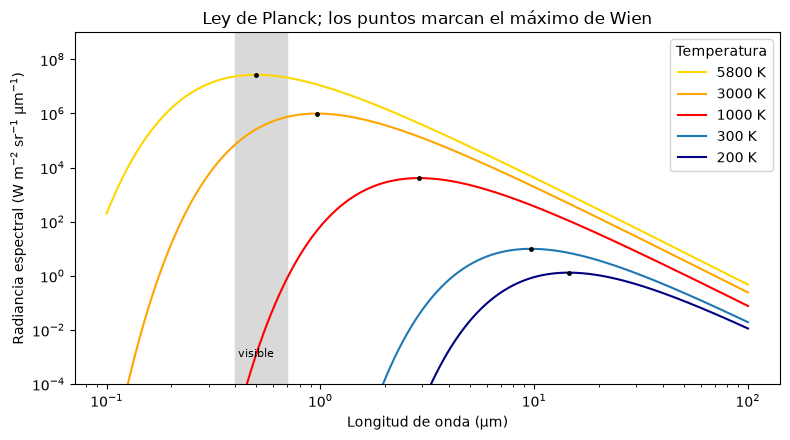

In [2]:
def planck(lam_um, T):
    """Radiancia espectral de un cuerpo negro en W m-2 sr-1 um-1."""
    lam = lam_um * 1e-6
    x = np.minimum(h * c / (lam * k * T), 700)          # evita el desbordamiento en longitudes de onda muy cortas
    B = 2 * h * c**2 / lam**5 / np.expm1(x)
    return B * 1e-6

lam = np.logspace(-1, 2, 800)   # de 0.1 a 100 um
fig, ax = plt.subplots(figsize=(8, 4.5))
for T, col in [(5800, 'gold'), (3000, 'orange'), (1000, 'red'), (300, 'tab:blue'), (200, 'navy')]:
    B = planck(lam, T)
    ax.loglog(lam, B, color=col, label=f'{T} K')
    lmax = 2898 / T
    ax.plot(lmax, planck(lmax, T), 'k.', ms=5)
ax.axvspan(0.4, 0.7, color='0.85', zorder=0)
ax.text(0.5, 1e-3, 'visible', ha='center', fontsize=8)
ax.set_ylim(1e-4, 1e9)
ax.set_xlabel('Longitud de onda (µm)')
ax.set_ylabel('Radiancia espectral (W m$^{-2}$ sr$^{-1}$ µm$^{-1}$)')
ax.set_title('Ley de Planck; los puntos marcan el máximo de Wien')
ax.legend(title='Temperatura')
plt.tight_layout()
plt.show()

La celda siguiente verifica las dos leyes: integra numéricamente la curva de Planck para comparar con $\sigma T^4$ y calcula la longitud de onda del máximo para el Sol, un incendio forestal, la superficie terrestre y una lava basáltica recién emitida. El ejemplo de la lava ilustra una aplicación geológica directa: los sensores de infrarrojo de onda corta y medio detectan la actividad volcánica porque el máximo de emisión de un flujo de lava cae en esas longitudes de onda.

In [3]:
sigma = 5.67e-8
lam_int = np.linspace(0.05, 1000, 400000)
for nombre, T in [('Sol', 5800), ('lava basáltica', 1400), ('incendio forestal', 1000), ('superficie terrestre', 300)]:
    M_num = np.pi * np.trapezoid(planck(lam_int, T), lam_int)   # emitancia = pi * radiancia integrada
    print(f'{nombre:20s} T = {T:5d} K  lambda_max = {2898/T:6.2f} um   '
          f'M (Planck) = {M_num:10.3e}  M (sigma T^4) = {sigma*T**4:10.3e} W m-2')

Sol                  T =  5800 K  lambda_max =   0.50 um   M (Planck) =  6.423e+07  M (sigma T^4) =  6.416e+07 W m-2
lava basáltica       T =  1400 K  lambda_max =   2.07 um   M (Planck) =  2.181e+05  M (sigma T^4) =  2.178e+05 W m-2
incendio forestal    T =  1000 K  lambda_max =   2.90 um   M (Planck) =  5.676e+04  M (sigma T^4) =  5.670e+04 W m-2
superficie terrestre T =   300 K  lambda_max =   9.66 um   M (Planck) =  4.598e+02  M (sigma T^4) =  4.593e+02 W m-2


## Radiación solar y terrestre en la parte alta de la atmósfera

La radiación solar que llega a la Tierra se reduce con el cuadrado de la distancia. Si el Sol emite como un cuerpo negro a 5800 K desde un radio de 6.96 × 10⁵ km, la irradiancia en el tope de la atmósfera, a una unidad astronómica (1.496 × 10⁸ km), es la constante solar, cercana a 1361 W m⁻². La comparación con la emisión de la Tierra en la misma escala de irradiancia muestra que en el infrarrojo térmico la energía emitida por la superficie supera ampliamente a la solar reflejada, lo que permite medir temperaturas de superficie de día y de noche.

Constante solar estimada: 1390 W m-2


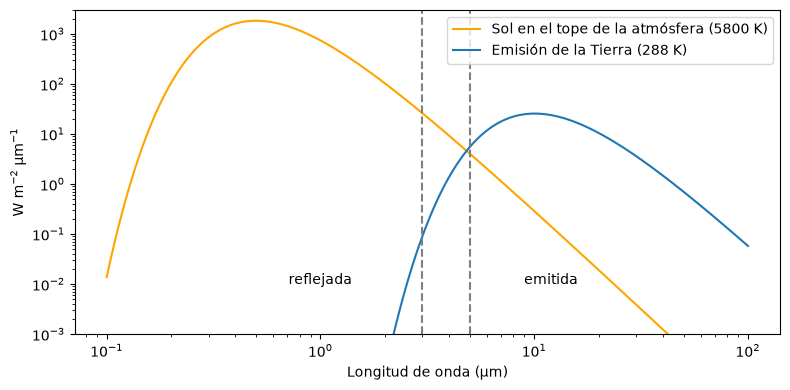

In [4]:
R_sol, d_ua = 6.96e8, 1.496e11
lam = np.logspace(-1, 2, 800)
E_sol = np.pi * planck(lam, 5800) * (R_sol / d_ua)**2       # irradiancia solar en el tope de la atmósfera
E_tierra = np.pi * planck(lam, 288)                           # emitancia de la Tierra
print(f'Constante solar estimada: {np.trapezoid(E_sol, lam):.0f} W m-2')
fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(lam, E_sol, color='orange', label='Sol en el tope de la atmósfera (5800 K)')
ax.loglog(lam, E_tierra, color='tab:blue', label='Emisión de la Tierra (288 K)')
ax.axvline(3, color='0.5', ls='--'); ax.axvline(5, color='0.5', ls='--')
ax.text(1.0, 1e-2, 'reflejada', ha='center'); ax.text(12, 1e-2, 'emitida', ha='center')
ax.set_ylim(1e-3, 3e3)
ax.set_xlabel('Longitud de onda (µm)'); ax.set_ylabel('W m$^{-2}$ µm$^{-1}$')
ax.legend(); plt.tight_layout(); plt.show()

## Emisividad y temperatura de brillo

Las superficies reales no son cuerpos negros: emiten una fracción $\varepsilon_\lambda$ de lo que emitiría un cuerpo negro a la misma temperatura, la emisividad. El agua tiene emisividades cercanas a 0.99 en el térmico, la vegetación alrededor de 0.98 y los minerales silicatados presentan mínimos de emisividad entre 8 y 10 µm (las bandas reststrahlen) que dependen del contenido de sílice, lo que permite cartografiar litologías con sensores térmicos multiespectrales como ASTER. Un sensor que no conoce la emisividad estima una temperatura de brillo, la temperatura del cuerpo negro que produciría la radiancia medida, siempre menor o igual que la temperatura real. La celda siguiente invierte la ley de Planck para mostrar el error que se comete al ignorar la emisividad.

In [5]:
def temp_brillo(L, lam_um):
    lam_m = lam_um * 1e-6
    return h * c / (lam_m * k * np.log(1 + 2 * h * c**2 / (lam_m**5 * L * 1e6)))

T_real, lam_b = 300.0, 10.9
for sup, eps in [('agua', 0.99), ('vegetación', 0.98), ('suelo seco', 0.94), ('cuarcita', 0.82)]:
    L = eps * planck(lam_b, T_real)
    print(f'{sup:11s} emisividad {eps:4.2f} -> temperatura de brillo {temp_brillo(L, lam_b):6.1f} K (real {T_real:.0f} K)')

agua        emisividad 0.99 -> temperatura de brillo  299.3 K (real 300 K)
vegetación  emisividad 0.98 -> temperatura de brillo  298.6 K (real 300 K)
suelo seco  emisividad 0.94 -> temperatura de brillo  295.9 K (real 300 K)
cuarcita    emisividad 0.82 -> temperatura de brillo  287.2 K (real 300 K)


## Para profundizar

El capítulo 2 de {cite}`chuvieco2008` y el capítulo 1 de {cite}`lillesand2015` desarrollan los principios físicos con más detalle. {cite:t}`tempfli2009` incluye ejercicios sencillos sobre las leyes de radiación, y {cite:t}`schowengerdt2007` trata la radiometría desde el punto de vista del procesamiento de imágenes.